# 03B · Experiment readout: what do quick-commerce ads really earn?

**What happened:** quick-commerce (QC) ads were switched off in Bengaluru and Hyderabad for weeks
88–95; the other 6 cities carried on as normal. This notebook reads the result **exactly as
pre-registered** in `preregistration/analysis_plan.md` (21 Oct 2026, before the data existed).

**The idea, simply:** a "twin" made of the untouched cities shows what Bengaluru + Hyderabad would
have sold with ads on. The gap between the real cities and their twin during the pause is what the
ads were truly worth.

In [ ]:
# Colab set-up: run this first (skipped automatically outside Colab)
import sys, os
if "google.colab" in sys.modules:
    REPO_URL = "https://github.com/anvesha2402/prakriti-growth-measurement.git"   # change if your repo differs
    if not os.path.exists("/content/repo"):
        get_ipython().system(f"git clone {REPO_URL} /content/repo")
    os.chdir("/content/repo")
    get_ipython().system("pip install -q 'pymc-marketing==1.1.*' statsmodels h5netcdf")


In [1]:
import sys, json, itertools
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src") if Path.cwd().name == "notebooks" else "src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import nnls
from scipy.stats import norm
from common import load, FULL, CHANNELS, LABEL, COLOR, INK, INK2, NEUTRAL, style, save, ROOT

style()
plan = json.loads((ROOT / "preregistration" / "design.json").read_text())
TREATED = plan["treated_geos"]
T0, T1 = plan["weeks"]                              # 88, 95
FIT = range(62, 88)                                 # pre-registered fit window: weeks 62–87 (26 weeks)
TEST = range(T0, T1 + 1)
w, _ = load(FULL)
assert w.week.max() == 104, "needs the full 104-week data"
GEOS = sorted(w.geo.unique())
CONTROLS = [g for g in GEOS if g not in TREATED]
Y = w.pivot(index="week", columns="geo", values="rev_quick_commerce_lakh")
SPEND = w.pivot(index="week", columns="geo", values="spend_qc_ads_lakh")
print(f"Treated: {TREATED} | Controls: {CONTROLS} | Test weeks {T0}–{T1}")

Treated: ['Bengaluru', 'Hyderabad'] | Controls: ['Ahmedabad', 'Chennai', 'Delhi NCR', 'Kolkata', 'Mumbai', 'Pune'] | Test weeks 88–95


## 1. Build the twin and measure the gap (primary estimator: synthetic control)

In [2]:
def twin(y, treated, donors, fit):
    W, _ = nnls(y.loc[fit, donors].values, y.loc[fit, treated].sum(1).values)
    return pd.Series(y[donors].values @ W, index=y.index), pd.Series(W, index=donors)

synth, W = twin(Y, TREATED, CONTROLS, FIT)
real = Y[TREATED].sum(1)
gap = real - synth
pre_gap = gap.loc[FIT].mean()
effect_wk = gap.loc[TEST].mean() - pre_gap                         # ₹ lakh per week (negative = sales lost)
base_wk = synth.loc[TEST].mean()
print("Twin weights:", W[W > 0].round(3).to_dict())
print(f"Effect during the pause: {effect_wk:+.2f} ₹ lakh per week ({effect_wk / base_wk:+.1%} of expected QC sales)")

Twin weights: {'Ahmedabad': 0.962, 'Delhi NCR': 0.228, 'Kolkata': 0.561, 'Mumbai': 0.022, 'Pune': 1.056}
Effect during the pause: -5.44 ₹ lakh per week (-16.0% of expected QC sales)


/tmp/ipykernel_296/712309747.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  W, _ = nnls(y.loc[fit, donors].values, y.loc[fit, treated].sum(1).values)
/tmp/ipykernel_296/712309747.py:6: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  real = Y[TREATED].sum(1)


## 2. How sure are we? (placebo in time, pre-registered)
Same estimator on every 8-week window in weeks 27–87, when nothing was switched off. Their spread
is the noise level.

In [3]:
def placebo_effect(start, y=Y, treated=TREATED, donors=CONTROLS, fit_len=26, length=8):
    fw, tw = range(start - fit_len, start), range(start, start + length)
    s, _ = twin(y, treated, donors, fw)
    g = y[treated].sum(1) - s
    return g.loc[tw].mean() - g.loc[fw].mean()

placebos = np.array([placebo_effect(s) for s in range(27, 81)])
se = placebos.std(ddof=1)
z = effect_wk / se
p_value = 2 * norm.sf(abs(z))
ci90 = (effect_wk - 1.645 * se, effect_wk + 1.645 * se)
ci95 = (effect_wk - 1.96 * se, effect_wk + 1.96 * se)
print(f"Noise (placebo SD): {se:.3f} ₹ lakh/week from {len(placebos)} windows")
print(f"Effect {effect_wk:+.2f}  | 90% CI {ci90[0]:+.2f} to {ci90[1]:+.2f}  | 95% CI {ci95[0]:+.2f} to {ci95[1]:+.2f}  | p {'< 0.001' if p_value < 0.001 else f'= {p_value:.3f}'}")

/tmp/ipykernel_296/712309747.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  W, _ = nnls(y.loc[fit, donors].values, y.loc[fit, treated].sum(1).values)
/tmp/ipykernel_296/2669592000.py:4: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  g = y[treated].sum(1) - s
/tmp/ipykernel_296/712309747.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  W, _ = nnls(y.loc[fit, donors].values, y.loc[fit, treated].sum(1).values)
/tmp/ipykernel_296/2669592000.py:4: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  g = y[treated].sum(1) - s
/tmp/ipykernel_296/712309747.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  W, _ = nnls(y.loc[fit, donors].values, y.loc[fit, treated].sum(1).values)
/tmp/ipykernel_296/2669592000.py:4: Pandas4Warning: Starting with pandas versio

/tmp/ipykernel_296/2669592000.py:4: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  g = y[treated].sum(1) - s
/tmp/ipykernel_296/712309747.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  W, _ = nnls(y.loc[fit, donors].values, y.loc[fit, treated].sum(1).values)
/tmp/ipykernel_296/2669592000.py:4: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  g = y[treated].sum(1) - s
/tmp/ipykernel_296/712309747.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  W, _ = nnls(y.loc[fit, donors].values, y.loc[fit, treated].sum(1).values)
/tmp/ipykernel_296/2669592000.py:4: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  g = y[treated].sum(1) - s
/tmp/ipykernel_296/712309747.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.

Noise (placebo SD): 0.142 ₹ lakh/week from 54 windows
Effect -5.44  | 90% CI -5.67 to -5.21  | 95% CI -5.72 to -5.16  | p < 0.001


/tmp/ipykernel_296/2669592000.py:4: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  g = y[treated].sum(1) - s
/tmp/ipykernel_296/712309747.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  W, _ = nnls(y.loc[fit, donors].values, y.loc[fit, treated].sum(1).values)
/tmp/ipykernel_296/2669592000.py:4: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  g = y[treated].sum(1) - s
/tmp/ipykernel_296/712309747.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  W, _ = nnls(y.loc[fit, donors].values, y.loc[fit, treated].sum(1).values)
/tmp/ipykernel_296/2669592000.py:4: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  g = y[treated].sum(1) - s
/tmp/ipykernel_296/712309747.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.

## 3. Validity checks (pre-registered; reported whatever the result)

In [4]:
fit_err = np.sqrt((gap.loc[FIT] - pre_gap).pow(2).mean()) / real.loc[FIT].mean()
check_gap = gap.loc[80:87].mean() - pre_gap
other = [c for c in CHANNELS if c != "qc_ads"]
ratio = {}
for c in other:
    S = w.pivot(index="week", columns="geo", values=f"spend_{c}_lakh")
    r_pre = S.loc[80:87, TREATED].sum().sum() / S.loc[80:87, CONTROLS].sum().sum()
    r_test = S.loc[TEST, TREATED].sum().sum() / S.loc[TEST, CONTROLS].sum().sum()
    ratio[LABEL[c]] = r_test / r_pre - 1
checks = pd.DataFrame([
    ("Twin fit error before the test", "< 3%", f"{fit_err:.1%}", fit_err < 0.03),
    ("Twin gap in check weeks 80–87", "≈ 0", f"{check_gap:+.2f} lakh/wk", abs(check_gap) < 2 * se),
    ("Other channels' spend shift in treated cities", "no change", f"max {max(abs(v) for v in ratio.values()):.1%}",
     max(abs(v) for v in ratio.values()) < 0.10),
], columns=["Check", "Rule", "Result", "Pass"])
VALID = bool(checks["Pass"].all())
print(checks.to_string(index=False))
print("Test is", "VALID" if VALID else "INCONCLUSIVE (a pre-registered check failed)")

                                        Check      Rule        Result  Pass
               Twin fit error before the test      < 3%          1.4%  True
                Twin gap in check weeks 80–87       ≈ 0 -0.01 lakh/wk  True
Other channels' spend shift in treated cities no change      max 5.6%  True
Test is VALID


## 4. Robustness (pre-registered)
**Placebo in space:** pretend each pair of *control* cities had been paused (using the other 4
controls as donors). The real effect should be far outside that spread.
**Difference-in-differences:** a simpler cross-check on log QC sales.

In [5]:
space = []
for pair in itertools.combinations(CONTROLS, 2):
    donors = [g for g in CONTROLS if g not in pair]
    s, _ = twin(Y, list(pair), donors, FIT)
    g = Y[list(pair)].sum(1) - s
    space.append((" + ".join(pair), (g.loc[TEST].mean() - g.loc[FIT].mean()) / s.loc[TEST].mean()))
space = pd.DataFrame(space, columns=["placebo pair", "effect_pct"])
real_pct = effect_wk / base_wk
rank = (space.effect_pct.abs() >= abs(real_pct)).sum()
print(f"Placebo in space: {len(space)} control pairs, largest |effect| {space.effect_pct.abs().max():.1%}; "
      f"real effect {real_pct:+.1%} (exceeded by {rank} of {len(space)})")

lt, lc = np.log(Y[TREATED].sum(1)), np.log(Y[CONTROLS].sum(1))
did_pct = np.expm1((lt.loc[TEST].mean() - lt.loc[FIT].mean()) - (lc.loc[TEST].mean() - lc.loc[FIT].mean()))
print(f"Difference-in-differences: {did_pct:+.1%} (synthetic control: {real_pct:+.1%})")

# secondary metric: total revenue (did lost QC sales move to other channels?)
YT = w.pivot(index="week", columns="geo", values="revenue_lakh")
sT, _ = twin(YT, TREATED, CONTROLS, FIT)
gT = YT[TREATED].sum(1) - sT
eff_total = gT.loc[TEST].mean() - gT.loc[FIT].mean()
print(f"Secondary, total revenue: {eff_total:+.2f} ₹ lakh/week (QC sales alone: {effect_wk:+.2f})")

Placebo in space: 15 control pairs, largest |effect| 2.5%; real effect -16.0% (exceeded by 0 of 15)
Difference-in-differences: -15.9% (synthetic control: -16.0%)


Secondary, total revenue: -5.72 ₹ lakh/week (QC sales alone: -5.44)


/tmp/ipykernel_296/712309747.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  W, _ = nnls(y.loc[fit, donors].values, y.loc[fit, treated].sum(1).values)
/tmp/ipykernel_296/780035954.py:5: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  g = Y[list(pair)].sum(1) - s
/tmp/ipykernel_296/712309747.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  W, _ = nnls(y.loc[fit, donors].values, y.loc[fit, treated].sum(1).values)
/tmp/ipykernel_296/780035954.py:5: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  g = Y[list(pair)].sum(1) - s
/tmp/ipykernel_296/712309747.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  W, _ = nnls(y.loc[fit, donors].values, y.loc[fit, treated].sum(1).values)
/tmp/ipykernel_296/780035954.py:5: Pandas4Warning: Starting with pandas ver

## 5. Turn the gap into ROI (pre-registered formula)
Spend withheld = treated cities' weekly QC spend in weeks 80–87 × how much control cities' spend
grew into the test weeks × 8 weeks.

In [6]:
growth = SPEND.loc[TEST, CONTROLS].sum(1).mean() / SPEND.loc[80:87, CONTROLS].sum(1).mean()
withheld = SPEND.loc[80:87, TREATED].sum(1).mean() * growth * len(TEST)
follow = range(T1 + 1, T1 + 3)
carry = gap.loc[follow].mean() - pre_gap
carry_sig = abs(carry) > 1.96 * se and carry < 0
lost = -effect_wk * len(TEST) + (-carry * len(follow) if carry_sig else 0.0)
roi = lost / withheld
roi_ci90 = tuple(-c * len(TEST) / withheld for c in ci90[::-1])
roi_ci95 = tuple(-c * len(TEST) / withheld for c in ci95[::-1])
print(f"Spend withheld: ₹{withheld:.1f} lakh | revenue lost: ₹{lost:.1f} lakh"
      + (f" (incl. carry-over weeks {follow.start}–{follow.stop - 1})" if carry_sig else " (no significant carry-over)"))
print(f"TEST ROI = ₹{roi:.2f} per ₹1   (90% CI {roi_ci90[0]:.2f}–{roi_ci90[1]:.2f}; 95% CI {roi_ci95[0]:.2f}–{roi_ci95[1]:.2f})")

Spend withheld: ₹39.4 lakh | revenue lost: ₹43.5 lakh (no significant carry-over)
TEST ROI = ₹1.11 per ₹1   (90% CI 1.06–1.15; 95% CI 1.05–1.16)


/tmp/ipykernel_296/4042728416.py:1: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  growth = SPEND.loc[TEST, CONTROLS].sum(1).mean() / SPEND.loc[80:87, CONTROLS].sum(1).mean()
/tmp/ipykernel_296/4042728416.py:1: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  growth = SPEND.loc[TEST, CONTROLS].sum(1).mean() / SPEND.loc[80:87, CONTROLS].sum(1).mean()
/tmp/ipykernel_296/4042728416.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  withheld = SPEND.loc[80:87, TREATED].sum(1).mean() * growth * len(TEST)


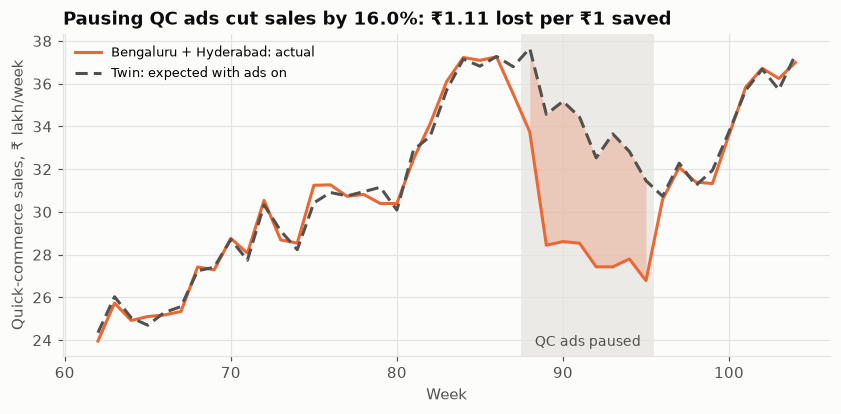

In [7]:
fig, ax = plt.subplots(figsize=(9, 3.8))
wk = list(range(62, 105))
ax.axvspan(T0 - 0.5, T1 + 0.5, color="#e4e3df", alpha=0.7, lw=0)
ax.plot(wk, real.loc[wk], color=COLOR["qc_ads"], label=f"{' + '.join(TREATED)}: actual")
ax.plot(wk, (synth + pre_gap).loc[wk], color=INK2, ls=(0, (4, 2)), label="Twin: expected with ads on")
ax.fill_between(list(TEST), real.loc[TEST], (synth + pre_gap).loc[TEST], color=COLOR["qc_ads"], alpha=0.25, lw=0)
ax.text((T0 + T1) / 2, ax.get_ylim()[0] + 0.3, "QC ads paused", ha="center", va="bottom", fontsize=9, color=INK2)
ax.set_xlabel("Week"); ax.set_ylabel("Quick-commerce sales, ₹ lakh/week")
ax.legend(frameon=False, fontsize=8.5, loc="upper left")
ax.set_title(f"Pausing QC ads cut sales by {abs(real_pct):.1%}: ₹{roi:.2f} lost per ₹1 saved")
save(fig, "03B_experiment_gap"); plt.show()

## 6. Compare with what MMM v1 believed

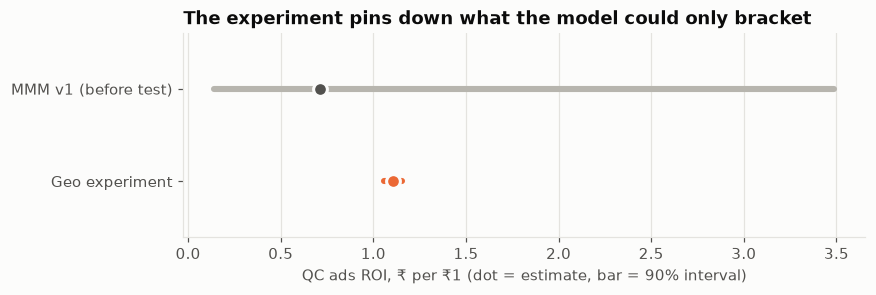

MMM v1: 0.71 (0.14–3.49) | Test: 1.11 (1.06–1.15) | test inside v1 interval: True | interval 35× narrower


In [8]:
v1 = pd.read_csv(ROOT / "model" / "mmm_v1_roi.csv").set_index("channel").loc["Quick-commerce ads"]
fig, ax = plt.subplots(figsize=(8, 2.4))
ax.plot([v1.roi_lo, v1.roi_hi], [1, 1], color=NEUTRAL, lw=4, solid_capstyle="round")
ax.plot(v1.roi, 1, "o", color=INK2, ms=9, mec="#fcfcfb", mew=2)
ax.plot([roi_ci90[0], roi_ci90[1]], [0, 0], color=COLOR["qc_ads"], lw=4, solid_capstyle="round")
ax.plot(roi, 0, "o", color=COLOR["qc_ads"], ms=9, mec="#fcfcfb", mew=2)
ax.set_yticks([0, 1], ["Geo experiment", "MMM v1 (before test)"]); ax.set_ylim(-0.6, 1.6)
ax.set_xlabel("QC ads ROI, ₹ per ₹1 (dot = estimate, bar = 90% interval)")
ax.grid(axis="y", visible=False)
ax.set_title("The experiment pins down what the model could only bracket")
save(fig, "03B_test_vs_mmm"); plt.show()
inside = v1.roi_lo <= roi <= v1.roi_hi
print(f"MMM v1: {v1.roi:.2f} ({v1.roi_lo:.2f}–{v1.roi_hi:.2f}) | Test: {roi:.2f} ({roi_ci90[0]:.2f}–{roi_ci90[1]:.2f}) | "
      f"test inside v1 interval: {inside} | interval {(v1.roi_hi - v1.roi_lo) / (roi_ci90[1] - roi_ci90[0]):.0f}× narrower")

## 7. Pre-registered decision

In [9]:
BREAKEVEN = 1 / 0.30
lo, hi = roi_ci90
if hi < 1.0:
    decision = "Cut: QC ads return less revenue than they cost. Move to the −50% bound and renegotiate placement fees."
elif hi < BREAKEVEN:
    decision = f"Reduce: QC ads add sales but lose contribution at today's spend (break-even ROI ≈ {BREAKEVEN:.1f}). Cut toward marginal ROI = {BREAKEVEN:.1f}."
elif lo > BREAKEVEN:
    decision = "Protect or grow: QC ads are profitable at the margin."
else:
    decision = "Hold: the interval straddles break-even; keep spend and use the result to calibrate MMM v2."
print("DECISION:", decision)

result = dict(channel="qc_ads", treated_geos=TREATED, weeks=[T0, T1], valid=VALID,
              effect_lakh_per_week=round(effect_wk, 4), se_lakh_per_week=round(se, 4), p_value=float(p_value),
              effect_pct=round(real_pct, 4), did_pct=round(float(did_pct), 4), spend_withheld_lakh=round(withheld, 3),
              revenue_lost_lakh=round(lost, 3), roi=round(roi, 4), roi_ci90=[round(x, 4) for x in roi_ci90],
              roi_ci95=[round(x, 4) for x in roi_ci95], carry_over_included=bool(carry_sig),
              secondary_total_revenue_effect_lakh_per_week=round(eff_total, 4), decision=decision)
(ROOT / "model" / "experiment_result.json").write_text(json.dumps(result, indent=1))
print("Saved model/experiment_result.json (feeds MMM v2 calibration)")

DECISION: Reduce: QC ads add sales but lose contribution at today's spend (break-even ROI ≈ 3.3). Cut toward marginal ROI = 3.3.
Saved model/experiment_result.json (feeds MMM v2 calibration)


## 8. So what

In [10]:
print("SO WHAT")
print(f"1. Result: switching QC ads off cut Bengaluru + Hyderabad quick-commerce sales by {abs(real_pct):.1%}. "
      f"Each ₹1 of QC ads brings back ₹{roi:.2f} (90% CI {roi_ci90[0]:.2f}–{roi_ci90[1]:.2f}); p {'< 0.001' if p_value < 0.001 else f'= {p_value:.3f}'}.")
print(f"2. Versus the platforms: they claim ₹7.54 per ₹1, about {7.54 / roi:.0f}× the measured effect. "
      f"Versus MMM v1: the measured {roi:.2f} sits {'inside' if inside else 'outside'} v1's interval ({v1.roi_lo:.2f}–{v1.roi_hi:.2f}), "
      f"but v1's median of {v1.roi:.2f} was {abs(v1.roi / roi - 1):.0%} too {'low' if v1.roi < roi else 'high'}; the test's interval is "
      f"{(v1.roi_hi - v1.roi_lo) / (roi_ci90[1] - roi_ci90[0]):.0f}× narrower.")
print(f"3. Decision (pre-registered): {decision}")
print("4. Sales lens: this gives the key-account team hard evidence for the Blinkit/Zepto negotiation "
      "(lower ad commitments or better placement terms). Next: feed the result into MMM v2 (Stage E).")

SO WHAT
1. Result: switching QC ads off cut Bengaluru + Hyderabad quick-commerce sales by 16.0%. Each ₹1 of QC ads brings back ₹1.11 (90% CI 1.06–1.15); p < 0.001.
2. Versus the platforms: they claim ₹7.54 per ₹1, about 7× the measured effect. Versus MMM v1: the measured 1.11 sits inside v1's interval (0.14–3.49), but v1's median of 0.71 was 35% too low; the test's interval is 35× narrower.
3. Decision (pre-registered): Reduce: QC ads add sales but lose contribution at today's spend (break-even ROI ≈ 3.3). Cut toward marginal ROI = 3.3.
4. Sales lens: this gives the key-account team hard evidence for the Blinkit/Zepto negotiation (lower ad commitments or better placement terms). Next: feed the result into MMM v2 (Stage E).
